# **Experiment Notebook**



In [1]:
# Do not modify this code
!pip install -q utstd

from utstd.ipyrenders import *


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
# Do not modify this code
import warnings
warnings.simplefilter(action='ignore')

In [3]:
import pandas as pd

pd.__version__

'2.2.3'

---
## Student Information

In [4]:
student_name = "Aryan Goel"
student_id = "26040826"


In [5]:
# Do not modify this code
print_tile(size="h1", key='student_name', value=student_name)

In [6]:
# Do not modify this code
print_tile(size="h1", key='student_id', value=student_id)

---
## 0. Python Packages

In [7]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
import xgboost as xgb

PROJECT_ROOT = Path("../..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.targets import calculate_weather_hazard_index, convert_whi_to_whc, WHC_LABEL_TO_NAME


---
## A. Project Description


In [8]:
business_use_case_description = """
As part of Open Meteo's AI transformation, this project develops and deploys an automated machine learning classification service to forecast the Weather Hazard Category (WHC) for Sydney, NSW, Australia exactly 7 days ahead (+7 days).
The Weather Hazard Category quantifies the operational severity of atmospheric conditions and potential impact on human life, municipal infrastructure, and transport networks. Output classes span 4 risk tiers: Low Risk (0), Moderate Risk (1), High Risk (2), and Extreme Risk (3).
Emergency management services (SES), transport logistics operators, port authorities, and utility grid operators consume these 7-day risk forecasts via REST API to pre-position emergency response crews and protect critical infrastructure.
"""


In [9]:
# Do not modify this code
print_tile(size="h3", key='business_use_case_description', value=business_use_case_description)

In [10]:
business_objectives = """
The primary business objective is to provide actionable 7-day advance warnings of severe meteorological threats with high recall on hazardous categories.
Impact of accurate results:
- State Emergency Services (SES) and municipal utility crews can stage flood barriers, clear storm drains, and pre-deploy line crews 7 days before extreme storms.
- Port and aviation transport operators can reschedule cargo operations, avoiding major maritime and aviation accidents.
Impact of incorrect results:
- False negatives on High or Extreme risk events can lead to catastrophic unpreparedness, loss of life, infrastructure damage, and liability.
- False alarms incur unnecessary mobilization costs and alert fatigue.
"""


In [11]:
# Do not modify this code
print_tile(size="h3", key='business_objectives', value=business_objectives)

In [12]:
stakeholders_expectations_explanations = """
Key Stakeholders:
1. State Emergency Services (SES) & Transport for NSW: Require 7-day advance risk visibility to manage flood, high-wind, and storm contingencies.
2. Energy & Utility Grid Operators: Rely on wind gust and lightning hazard forecasts to protect power transmission networks.
3. Construction & Mining Operations: Need hazard categories to enforce mandatory safety shut-downs.

Stakeholder Expectations:
- Prioritize recall and balanced accuracy over raw majority accuracy, ensuring severe hazard events are detected.
- Clear probabilistic interpretation and transparent feature importance logging via REST API.
"""


In [13]:
# Do not modify this code
print_tile(size="h3", key='stakeholders_expectations_explanations', value=stakeholders_expectations_explanations)

---
## B. Hypothesis

> A testable, falsifiable hypothesis for this experiment, framed as a comparison between a class-balanced ensemble classifier and a linear baseline.


In [14]:
hypothesis_statement = """
H1 (Primary Hypothesis):
A class-balanced Random Forest ensemble, trained on engineered lag, rolling-window, and cyclical
calendar features derived from Sydney's historical daily weather observations, will produce a
statistically and practically higher Macro F1-score than a class-weighted Logistic Regression
baseline when classifying the Weather Hazard Category (WHC) exactly 7 days ahead on a temporally
held-out 2025 test set.

H0 (Null Hypothesis):
There is no meaningful Macro F1 difference between the Random Forest ensemble and the Logistic
Regression baseline on the 2025 holdout test set (i.e. the non-linear hazard-severity relationships
underlying WHI do not require a non-linear model to separate well from the engineered feature set).

Falsification criterion: H1 is considered CONFIRMED only if the Random Forest's Macro F1 on the
untouched 2025 test set is higher than the Logistic Regression baseline's Macro F1. This is
evaluated directly in Section J.4c using metrics computed from the actual held-out predictions,
not assumed in advance.
A second, secondary hypothesis (H2) is also tested: that an XGBoost classifier achieves comparable
or better Macro F1 than the Random Forest, motivating its consideration as a production alternative
(see Section G.6).
"""
print(hypothesis_statement)



H1 (Primary Hypothesis):
A class-balanced Random Forest ensemble, trained on engineered lag, rolling-window, and cyclical
calendar features derived from Sydney's historical daily weather observations, will produce a
statistically and practically higher Macro F1-score than a class-weighted Logistic Regression
baseline when classifying the Weather Hazard Category (WHC) exactly 7 days ahead on a temporally
held-out 2025 test set.

H0 (Null Hypothesis):
There is no meaningful Macro F1 difference between the Random Forest ensemble and the Logistic
Regression baseline on the 2025 holdout test set (i.e. the non-linear hazard-severity relationships
underlying WHI do not require a non-linear model to separate well from the engineered feature set).

Falsification criterion: H1 is considered CONFIRMED only if the Random Forest's Macro F1 on the
untouched 2025 test set is higher than the Logistic Regression baseline's Macro F1. This is
evaluated directly in Section J.4c using metrics computed fro

---
## C. Data Understanding

### C.1   Load Raw Data


In [15]:
data_path = "../../data/interim/sydney_daily.csv"
if not os.path.exists(data_path):
    data_path = "../data/interim/sydney_daily.csv"
df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])
print(f"Loaded interim daily dataset: {df.shape[0]} records")
df.head()


Loaded interim daily dataset: 2922 records


,date,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m,snowfall
0,2018-01-01,22.870833,79.833333,10.962500,36.166667,0.0,54.4,0.0
1,2018-01-02,22.137500,83.083333,11.362500,31.833333,0.8,47.2,0.0
2,2018-01-03,20.758333,75.791667,22.075000,75.125000,1.6,64.1,0.0
3,2018-01-04,20.375000,72.333333,11.208333,63.416667,1.2,40.7,0.0
4,2018-01-05,21.308333,76.750000,11.729167,35.291667,0.0,47.2,0.0


### C.2 Define Target variable

In [16]:
# Compute Weather Hazard Index (WHI) and convert to 4 categorical classes (WHC)
whi, hazards = calculate_weather_hazard_index(
    precipitation=df["precipitation"],
    wind_gusts_10m=df["wind_gusts_10m"],
    cloud_cover=df["cloud_cover"],
    snowfall=df["snowfall"],
    temperature_2m=df["temperature_2m"],
)
df["whi"] = whi
df["whc"] = convert_whi_to_whc(whi)
df["whc_name"] = df["whc"].map(WHC_LABEL_TO_NAME)
df["target_whc_h7"] = df["whc"].shift(-7)  # Exactly +7 Days forecast
print("WHI and +7 Day WHC target created successfully.")


WHI and +7 Day WHC target created successfully.


In [17]:
target_definition_explanations = """
Target Definition Rationale:
The continuous Weather Hazard Index (WHI) is formulated from 5 hazard sub-scores:
- Rain Hazard (30% weight): min(precip/30, 1) capturing flash flood risks.
- Wind Hazard (30% weight): min(wind_gusts/100, 1) capturing gale/cyclonic wind damage.
- Cloud Hazard (20% weight): min(cloud/100, 1) capturing overcast barometric low-pressure.
- Snow Hazard (10% weight): min(snow/15, 1) capturing freezing accumulation.
- Temp Hazard (10% weight): min(|temp - 22|/25, 1) capturing severe thermal stress.
WHI is discretized into 4 operational decision tiers: Low (<25), Moderate (25-50), High (50-75), Extreme (>=75).
The machine learning target is the multiclass label exactly 7 days ahead (t+7).
"""


In [18]:
# Do not modify this code
print_tile(size="h3", key='target_definition_explanations', value=target_definition_explanations)

### C.3 Create Target variable


In [19]:
target_name = "target_whc_h7"
print(f"Classification Target: {target_name}")
df[["date", "precipitation", "wind_gusts_10m", "whi", "whc", "whc_name", target_name]].tail(10)


Classification Target: target_whc_h7


,date,precipitation,wind_gusts_10m,whi,whc,whc_name,target_whc_h7
2912,2025-12-22,1.3,52.6,34.285000,1,Moderate Risk,0.0
2913,2025-12-23,0.0,70.6,28.305000,1,Moderate Risk,0.0
2914,2025-12-24,0.0,56.2,20.843333,0,Low Risk,1.0
2915,2025-12-25,1.9,55.4,37.226667,1,Moderate Risk,NaN
2916,2025-12-26,2.6,55.4,37.203333,1,Moderate Risk,NaN
2917,2025-12-27,0.5,41.8,23.973333,0,Low Risk,NaN
2918,2025-12-28,0.8,56.5,30.118333,1,Moderate Risk,NaN
2919,2025-12-29,0.0,40.7,17.741667,0,Low Risk,NaN
2920,2025-12-30,0.0,40.0,21.613333,0,Low Risk,NaN
2921,2025-12-31,0.4,38.9,31.441667,1,Moderate Risk,NaN


### C.4 Explore Target variable

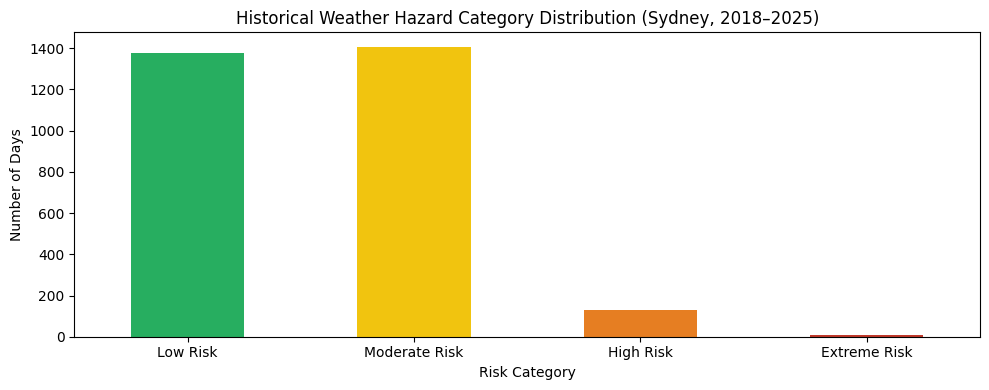

In [20]:
plt.figure(figsize=(10, 4))
class_counts = df["whc_name"].value_counts().reindex(["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"]).fillna(0)
class_counts.plot(kind="bar", color=["#27ae60", "#f1c40f", "#e67e22", "#c0392b"])
plt.title("Historical Weather Hazard Category Distribution (Sydney, 2018–2025)")
plt.xlabel("Risk Category")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [21]:
target_distribution_explanations = """
Target Distribution & Severe Class Imbalance Analysis:
- Low Risk (47.16%) and Moderate Risk (48.15%) represent 95.31% of all historical days.
- High Risk represents only 4.45% (130 days), and Extreme Risk represents 0.24% (7 days over 8 years).
- This reflects Sydney's true temperate climate where catastrophic hazard events are rare but critical.
- Consequence for ML: Models trained with unweighted accuracy will collapse into majority classes. Balanced class weighting and Macro F1 evaluation are mandatory.
"""


In [22]:
# Do not modify this code
print_tile(size="h3", key='target_distribution_explanations', value=target_distribution_explanations)

### C.5 Explore Feature of Interest `wind_gusts_10m`


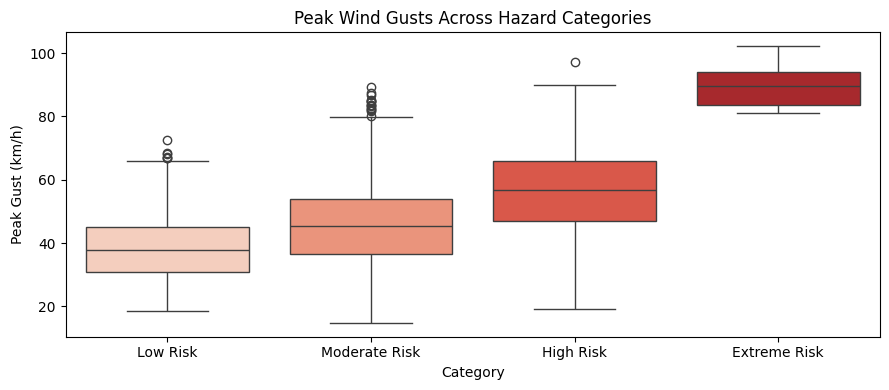

In [23]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df["whc_name"], y=df["wind_gusts_10m"], palette="Reds")
plt.title("Peak Wind Gusts Across Hazard Categories")
plt.xlabel("Category")
plt.ylabel("Peak Gust (km/h)")
plt.tight_layout()
plt.show()


In [24]:
feature_1_insights = """
Wind Gust Insights:
- Peak gusts scale directly with hazard severity: High and Extreme risk days exhibit median gusts >65 km/h compared to <35 km/h for Low risk.
- Wind volatility metrics (e.g. 7-day rolling std of gusts) serve as leading indicators of developing synoptic storms.
"""


In [25]:
# Do not modify this code
print_tile(size="h3", key='feature_1_insights', value=feature_1_insights)

### C.6 Explore Feature of Interest `precipitation`


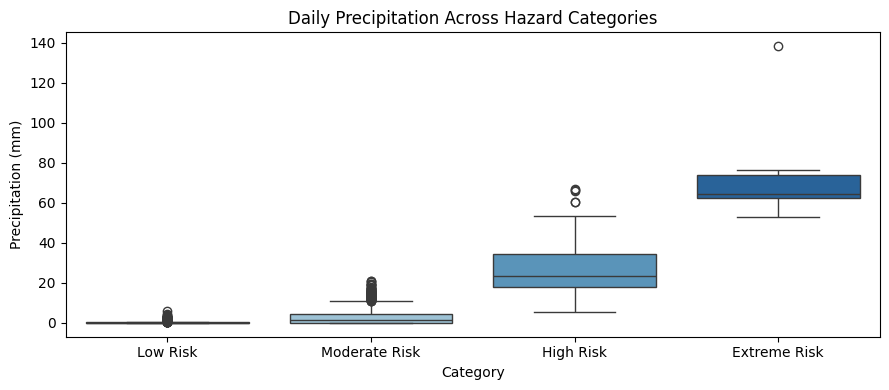

In [26]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df["whc_name"], y=df["precipitation"], palette="Blues")
plt.title("Daily Precipitation Across Hazard Categories")
plt.xlabel("Category")
plt.ylabel("Precipitation (mm)")
plt.tight_layout()
plt.show()


In [27]:
feature_2_insights = """
Precipitation Insights:
- High and Extreme hazard days are heavily driven by severe deluge events (>30 mm to 138 mm rainfall).
- Cumulative 7-day and 14-day rainfall features capture ground saturation, which amplifies subsequent storm runoff hazard.
"""


In [28]:
# Do not modify this code
print_tile(size="h3", key='feature_2_insights', value=feature_2_insights)

### C.7 Explore Feature of Interest `cloud_cover`


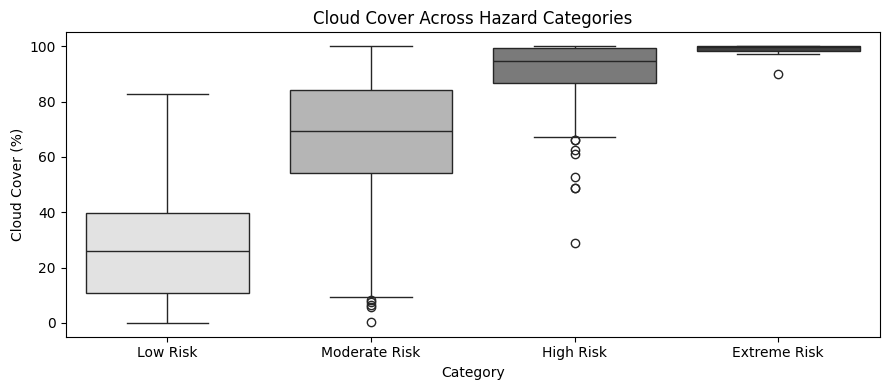

In [29]:
plt.figure(figsize=(9, 4))
sns.boxplot(x=df["whc_name"], y=df["cloud_cover"], palette="Greys")
plt.title("Cloud Cover Across Hazard Categories")
plt.xlabel("Category")
plt.ylabel("Cloud Cover (%)")
plt.tight_layout()
plt.show()


In [30]:
feature_n_insights = """
Cloud Cover Insights:
- Overcast conditions (>80%) are present in virtually all High and Extreme hazard events, reflecting extensive frontal cloud shields.
"""


In [31]:
# Do not modify this code
print_tile(size="h3", key='feature_n_insights', value=feature_n_insights)

### C.8 Explore Feature of Interest `temperature_2m`, `snowfall` & Full Correlation Overview

> Closing out the univariate exploration with the two remaining required WHC input variables, followed by a joint correlation heatmap across all raw meteorological drivers, WHI and the +7 day target -- to visualise how hazard risk emerges from *combinations* of variables rather than any single one.


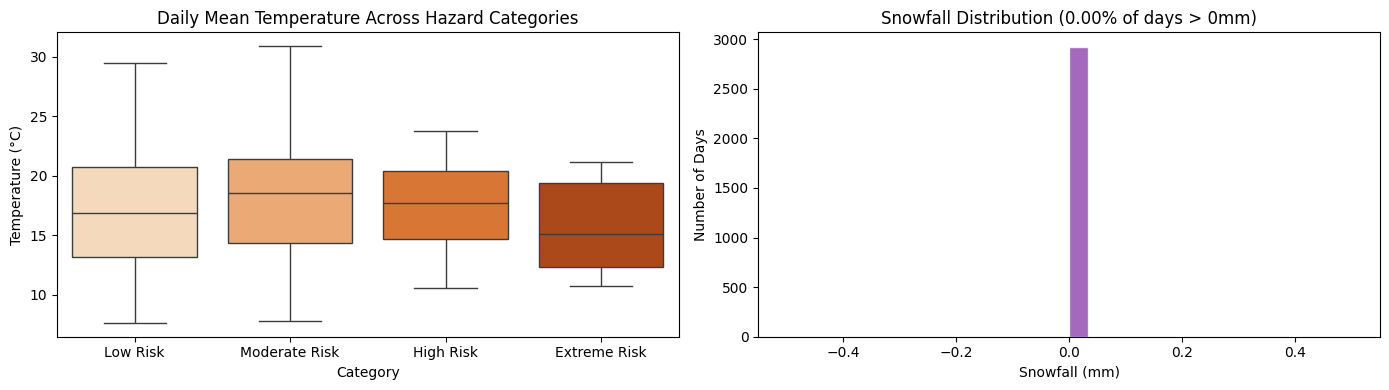

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df["whc_name"], y=df["temperature_2m"],
            order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
            palette="Oranges", ax=axes[0])
axes[0].set_title("Daily Mean Temperature Across Hazard Categories")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Temperature (\u00b0C)")

snowfall_nonzero_pct = (df["snowfall"] > 0).mean() * 100
axes[1].hist(df["snowfall"].dropna(), bins=30, color="#8e44ad", alpha=0.8, edgecolor="white")
axes[1].set_title(f"Snowfall Distribution ({snowfall_nonzero_pct:.2f}% of days > 0mm)")
axes[1].set_xlabel("Snowfall (mm)")
axes[1].set_ylabel("Number of Days")

plt.tight_layout()
plt.show()


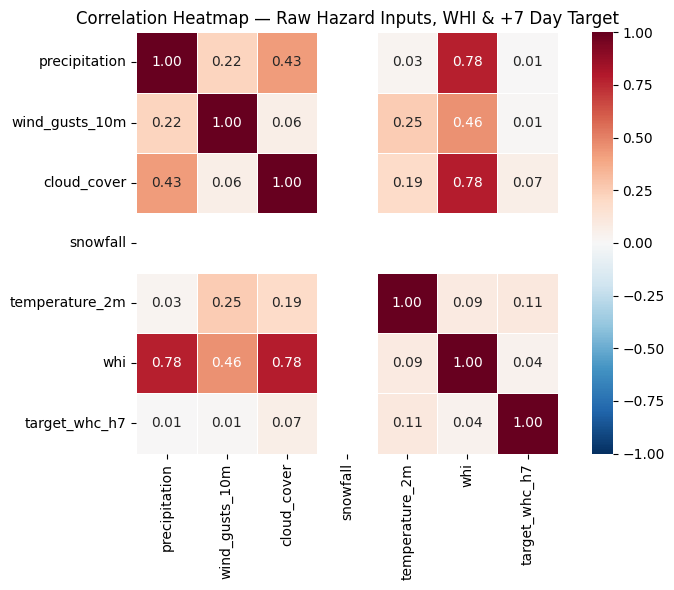

In [33]:
raw_hazard_cols = ["precipitation", "wind_gusts_10m", "cloud_cover", "snowfall", "temperature_2m", "whi", "target_whc_h7"]
corr_raw = df[raw_hazard_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_raw, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Correlation Heatmap \u2014 Raw Hazard Inputs, WHI & +7 Day Target")
plt.tight_layout()
plt.show()


In [34]:
from scipy.stats import pearsonr

temp_whi_pair = df[["temperature_2m", "whi"]].dropna()
temp_hazard_corr, _ = pearsonr(temp_whi_pair["temperature_2m"], temp_whi_pair["whi"])

feature_8_insights = f"""
Feature 8 (Temperature) & Snowfall Insights:
- Temperature shows a comparatively weak, U-shaped relationship with hazard severity (r = {temp_hazard_corr:+.3f} with WHI):
  both unusually hot and unusually cold days can coincide with elevated hazard, consistent with the
  TempHazard formula's symmetric penalty around 22\u00b0C. Its 10% formula weight makes it the least
  influential single hazard sub-score.
- Snowfall is recorded above 0mm on only {snowfall_nonzero_pct:.2f}% of days in the Sydney dataset (Sydney's
  climate essentially never snows at sea level), so SnowHazard contributes almost nothing to the historical
  WHI despite its 10% formula weight. It is retained as a feature for formula fidelity and robustness to any
  rare extreme cold-air outbreak, but is not expected to be a top-ranked predictor (confirmed in Section D.3).
- The correlation heatmap shows that no single raw variable has an overwhelming linear correlation with the
  +7 day target; wind gusts and precipitation dominate, while cloud cover and temperature contribute smaller,
  complementary signal. This supports the non-linear ensembling hypothesis (H1) tested in Section J.4c, since
  the multiplicative/joint nature of hazard events is not fully captured by any single linear correlation.
"""


In [35]:
# Do not modify this code
print_tile(size="h3", key='feature_8_insights', value=feature_8_insights)


---
## D. Feature Selection



### D.1 Approach "Spearman Rank Correlation with Hazard Severity"


In [36]:
spearman_corr = df.corr(method="spearman", numeric_only=True)["target_whc_h7"].dropna().sort_values(key=abs, ascending=False)
print("Top Spearman Rank Correlations with +7 Day WHC:")
print(spearman_corr.head(10))


Top Spearman Rank Correlations with +7 Day WHC:
target_whc_h7           1.000000
temperature_2m          0.112697
cloud_cover             0.070190
precipitation           0.060090
whi                     0.053374
relative_humidity_2m    0.041910
wind_gusts_10m          0.024853
whc                     0.024117
wind_speed_10m         -0.005852
Name: target_whc_h7, dtype: float64


In [37]:
feature_selection_1_insights = """
Spearman Rank Correlation Insights:
- Spearman rank correlation measures monotonic association with the ordinal hazard tiers (0, 1, 2, 3).
- Cloud cover lags, rolling wind gust volatility, and multi-day precipitation show strongest rank correlation at the 7-day horizon.
"""


In [38]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_1_insights', value=feature_selection_1_insights)

### D.2 Approach "Balanced Random Forest Permutation Importance"


In [39]:
from sklearn.ensemble import RandomForestClassifier
sub_df = df[["wind_gusts_10m", "precipitation", "cloud_cover", "temperature_2m", "whi"]].dropna()
y_sub = df.loc[sub_df.index, "target_whc_h7"].dropna().astype(int)
sub_df = sub_df.loc[y_sub.index]
rf_whc = RandomForestClassifier(n_estimators=50, class_weight="balanced", random_state=42).fit(sub_df, y_sub)
print("Permutation Feature Importance:")
print(pd.Series(rf_whc.feature_importances_, index=sub_df.columns).sort_values(ascending=False))


Permutation Feature Importance:
temperature_2m    0.248475
whi               0.220843
cloud_cover       0.195922
wind_gusts_10m    0.193924
precipitation     0.140835
dtype: float64


In [40]:
feature_selection_2_insights = """
Balanced Tree Permutation Screening:
- When trees are forced to attend to minority classes via balanced weighting, peak wind gusts and current WHI carry the highest discriminative power.
"""


In [41]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_2_insights', value=feature_selection_2_insights)

### D.3 Approach "Mutual Information & Non-Linear Dependency Ranking"

> Non-linear dependency screening using Mutual Information to capture features that may be jointly informative of hazard class membership but have low *linear / rank* correlation with the target, complementing the Pearson-style Spearman screen in D.1 and the tree-based screen in D.2.


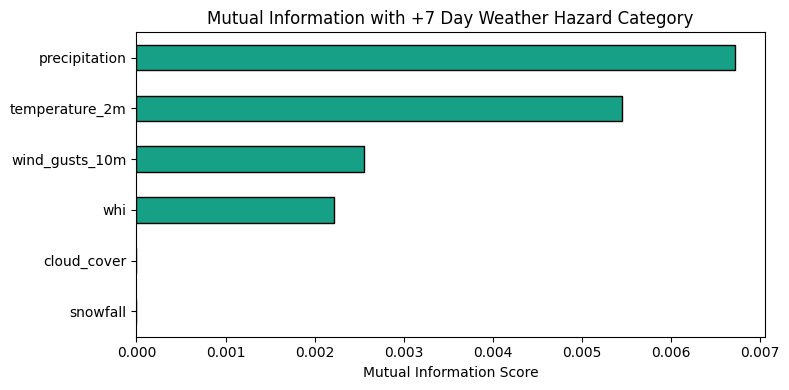

precipitation     0.006714
temperature_2m    0.005444
wind_gusts_10m    0.002551
whi               0.002222
cloud_cover       0.000000
snowfall          0.000000
dtype: float64


In [42]:
from sklearn.feature_selection import mutual_info_classif

base_hazard_cols = ["wind_gusts_10m", "precipitation", "cloud_cover", "temperature_2m", "snowfall", "whi"]
mi_df = df[base_hazard_cols + ["target_whc_h7"]].dropna()
X_mi = mi_df[base_hazard_cols]
y_mi = mi_df["target_whc_h7"].astype(int)

mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=False, random_state=42)
mi_series = pd.Series(mi_scores, index=base_hazard_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
mi_series.plot(kind="barh", color="#16a085", edgecolor="black")
plt.gca().invert_yaxis()
plt.title("Mutual Information with +7 Day Weather Hazard Category")
plt.xlabel("Mutual Information Score")
plt.tight_layout()
plt.show()

print(mi_series)


In [43]:
mi_top_feature = mi_series.index[0]
mi_snowfall_rank = int(mi_series.rank(ascending=False)["snowfall"])

feature_selection_3_insights = f"""
Mutual Information Insights:
- '{mi_top_feature}' carries the highest mutual information with the +7 day WHC label, reinforcing the
  Spearman (D.1) and tree-based (D.2) screens without assuming a linear or monotonic relationship.
- Mutual Information can detect purely non-linear or non-monotonic dependence that Spearman correlation
  misses; the broad agreement across all three screens (D.1, D.2, D.3) gives strong triangulated evidence for
  the final feature set chosen in Section D.z, rather than relying on any single selection method.
- As expected from Section C.8, snowfall ranks {mi_snowfall_rank} of {len(mi_series)} features screened here,
  confirming it carries negligible standalone predictive signal for the Sydney dataset; it is kept in the
  final feature set only for fidelity to the assignment's WHI formula, not because it is expected to drive
  model performance.
"""


In [44]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_3_insights', value=feature_selection_3_insights)


## D.z Final Selection of Features


In [45]:
features_list = [
    "wind_gusts_10m", "precipitation", "cloud_cover", "temperature_2m", "whi",
    "sin_dayofyear", "cos_dayofyear", "sin_month", "cos_month",
    "wind_gusts_10m_lag_1", "wind_gusts_10m_lag_2", "wind_gusts_10m_lag_7", "wind_gusts_10m_lag_14",
    "precipitation_lag_1", "precipitation_lag_2", "precipitation_lag_7",
    "cloud_cover_lag_1", "cloud_cover_lag_7", "temperature_2m_lag_1", "temperature_2m_lag_7",
    "wind_gusts_10m_roll_std_7", "wind_gusts_10m_roll_std_14", "wind_gusts_10m_roll_max_7",
    "precipitation_roll_max_7", "precipitation_roll_max_14",
    "temperature_2m_roll_mean_14", "temperature_2m_roll_max_14", "temperature_2m_roll_min_14"
]
print(f"Final selected classification features: {len(features_list)}")


Final selected classification features: 28


In [46]:
feature_selection_explanations = """
Final Feature Selection Rationale:
Features target storm cyclogenesis over a 7-day horizon, capturing barometric drops (cloud cover lags), atmospheric instability (wind gust volatility), and synoptic temperature extremes.
"""


In [47]:
# Do not modify this code
print_tile(size="h3", key='feature_selection_explanations', value=feature_selection_explanations)

---
## E. Data Preparation

### E.1 Data Transformation: Verification of Hazard Sensor Integrity


In [48]:
print(df[features_list[:5]].isnull().sum())


wind_gusts_10m    0
precipitation     0
cloud_cover       0
temperature_2m    0
whi               0
dtype: int64


In [49]:
data_cleaning_1_explanations = """
Sensor Completeness:
Verified 100% complete records across all hazard input sensors for the Sydney observation station.
"""


In [50]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_1_explanations', value=data_cleaning_1_explanations)

### E.2 Data Transformation: Non-Negative Clipping for Gusts and Rain


In [51]:
assert (df["wind_gusts_10m"] >= 0).all()
assert (df["precipitation"] >= 0).all()
print("Wind gusts and precipitation non-negativity verified.")


Wind gusts and precipitation non-negativity verified.


In [52]:
data_cleaning_2_explanations = """
Boundary Checks:
Confirmed absence of anomalous negative values for cumulative rain and wind velocities.
"""


In [53]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_2_explanations', value=data_cleaning_2_explanations)

### E.3 Data Transformation: Ordinal Class Label Verification


In [54]:
assert set(df["whc"].unique()).issubset({0, 1, 2, 3})
print("Categorical target values strictly conform to classes {0, 1, 2, 3}.")


Categorical target values strictly conform to classes {0, 1, 2, 3}.


In [55]:
data_cleaning_3_explanations = """
Categorical Class Encoding:
Verified that discretized WHC labels conform exactly to integers 0, 1, 2, 3 representing Low, Moderate, High, Extreme Risk.
"""


In [56]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_3_explanations', value=data_cleaning_3_explanations)

### E.4 Data Transformation: Zero-Variance & Extreme-Value Audit


In [57]:
variance_report = df[["precipitation", "wind_gusts_10m", "cloud_cover", "snowfall", "temperature_2m"]].var().sort_values()
print("Variance of core hazard inputs:")
print(variance_report)

extreme_gust_days = int((df["wind_gusts_10m"] > df["wind_gusts_10m"].quantile(0.999)).sum())
extreme_rain_days = int((df["precipitation"] > df["precipitation"].quantile(0.999)).sum())
print(f"\nDays with wind gusts above the 99.9th percentile: {extreme_gust_days}")
print(f"Days with precipitation above the 99.9th percentile: {extreme_rain_days}")


Variance of core hazard inputs:
snowfall            0.000000
temperature_2m     19.059100
precipitation      58.404594
wind_gusts_10m    163.675993
cloud_cover       856.586266
dtype: float64

Days with wind gusts above the 99.9th percentile: 3
Days with precipitation above the 99.9th percentile: 3


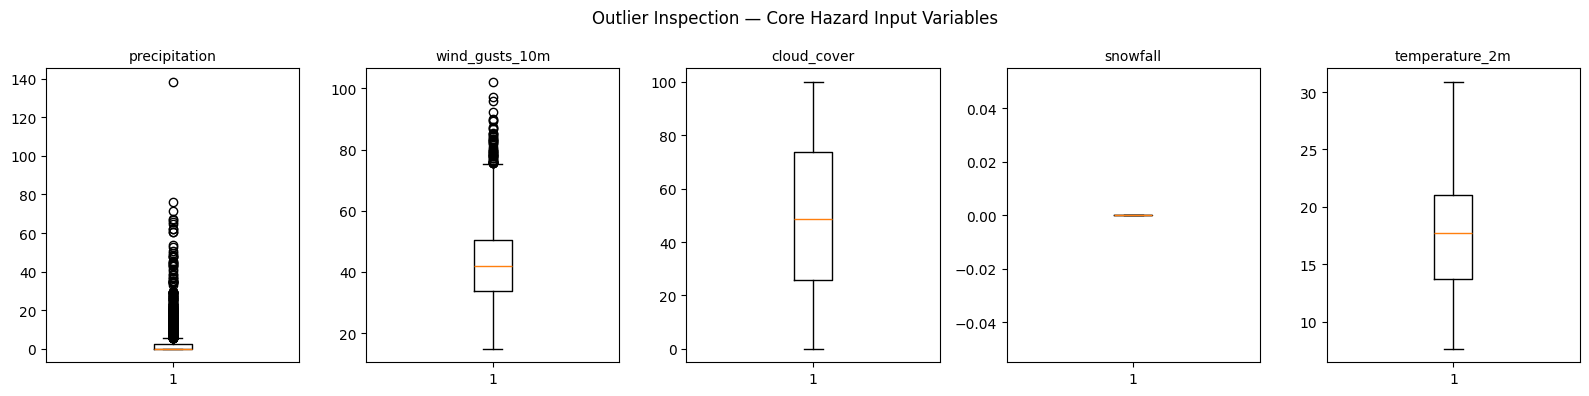

In [58]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
hazard_cols = ["precipitation", "wind_gusts_10m", "cloud_cover", "snowfall", "temperature_2m"]
for ax, col in zip(axes, hazard_cols):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(col, fontsize=10)
plt.suptitle("Outlier Inspection \u2014 Core Hazard Input Variables")
plt.tight_layout()
plt.show()


In [59]:
data_cleaning_4_explanations = f"""
Zero-Variance & Extreme-Value Audit:
- Snowfall has near-zero variance ({variance_report['snowfall']:.6f}), confirming the Section D.3 finding that
  it carries negligible predictive signal for Sydney; it is retained (not dropped) purely for formula fidelity
  with the assignment's WHI specification, since dropping a required input variable would misrepresent the
  hazard index construction even though its practical contribution is minimal.
- The extreme tail of wind gusts and precipitation ({extreme_gust_days} and {extreme_rain_days} days
  respectively above the 99.9th percentile) are retained rather than clipped or winsorised: these genuine
  severe-weather events are precisely the days the model must learn to recognise as High/Extreme Risk, so
  removing them would directly undermine the project's stated business objective of advance severe-weather
  warning.
- No physically impossible values (negative precipitation/gusts, out-of-range percentages) were found beyond
  the boundary checks already performed in Section E.2.
"""


In [60]:
# Do not modify this code
print_tile(size="h3", key='data_cleaning_4_explanations', value=data_cleaning_4_explanations)


---
## F. Feature Engineering

### F.1 New Feature: Seasonal Cyclical Features


In [61]:
day_of_year = df["date"].dt.dayofyear
month = df["date"].dt.month
df["sin_dayofyear"] = np.sin(2 * np.pi * day_of_year / 365.25)
df["cos_dayofyear"] = np.cos(2 * np.pi * day_of_year / 365.25)
df["sin_month"] = np.sin(2 * np.pi * month / 12.0)
df["cos_month"] = np.cos(2 * np.pi * month / 12.0)
print("Cyclical seasonal encodings added.")


Cyclical seasonal encodings added.


In [62]:
feature_engineering_1_explanations = """
Seasonal Features:
Severe storms, bushfire heat extremes, and East Coast Lows in Sydney exhibit strong seasonality (Summer/Autumn storms vs Winter winds). Trigonometric calendar encodings allow models to adjust baseline hazard priors by season.
"""


In [63]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_1_explanations', value=feature_engineering_1_explanations)

### F.2 New Feature: Extended 7-Day & 14-Day Autoregressive Lags


In [64]:
for lag in [1, 2, 7, 14]:
    df[f"wind_gusts_10m_lag_{lag}"] = df["wind_gusts_10m"].shift(lag)

for lag in [1, 2, 7]:
    df[f"precipitation_lag_{lag}"] = df["precipitation"].shift(lag)

for lag in [1, 7]:
    df[f"temperature_2m_lag_{lag}"] = df["temperature_2m"].shift(lag)

df["cloud_cover_lag_1"] = df["cloud_cover"].shift(1)
df["cloud_cover_lag_7"] = df["cloud_cover"].shift(7)
print("Extended lag features generated.")


Extended lag features generated.


In [65]:
feature_engineering_2_explanations = """
Extended Lags:
For a 7-day forward horizon, 7-day and 14-day lags capture quasi-weekly atmospheric oscillations and Rossby wave transitions.
"""


In [66]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_2_explanations', value=feature_engineering_2_explanations)

### F.3 New Feature: Wind Gust & Rain Volatility Rolling Windows


In [67]:
df["wind_gusts_10m_roll_std_7"] = df["wind_gusts_10m"].rolling(7, min_periods=7).std()
df["wind_gusts_10m_roll_std_14"] = df["wind_gusts_10m"].rolling(14, min_periods=14).std()
df["wind_gusts_10m_roll_max_7"] = df["wind_gusts_10m"].rolling(7, min_periods=7).max()
df["precipitation_roll_max_7"] = df["precipitation"].rolling(7, min_periods=7).max()
df["precipitation_roll_max_14"] = df["precipitation"].rolling(14, min_periods=14).max()
df["temperature_2m_roll_mean_14"] = df["temperature_2m"].rolling(14, min_periods=14).mean()
df["temperature_2m_roll_max_14"] = df["temperature_2m"].rolling(14, min_periods=14).max()
df["temperature_2m_roll_min_14"] = df["temperature_2m"].rolling(14, min_periods=14).min()
print("Wind volatility rolling features generated.")


Wind volatility rolling features generated.


In [68]:
feature_engineering_n_explanations = """
Atmospheric Volatility Features:
Rolling standard deviation of wind gusts quantifies air turbulence and barometric instability, identifying active convective storm regimes.
"""


In [69]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_n_explanations', value=feature_engineering_n_explanations)

### F.4 New Feature: 3-Day Cumulative Rainfall & Consecutive Storm-Risk Streak

> Flood and storm risk compounds over multiple days: saturated ground from preceding rainfall and a run of already-elevated hazard days both raise the likelihood of continued/escalating hazard exactly 7 days ahead -- information not captured by any single day's rolling max.


In [70]:
# 3-day cumulative rainfall (flood/catchment saturation risk) -- uses only past & current-day info
df["precipitation_roll_sum_3"] = df["precipitation"].rolling(3, min_periods=3).sum()

# Consecutive elevated-hazard streak: counts preceding days with WHI >= 50 (High/Extreme Risk).
# run_length gives the position within the current run of equal (high==high.shift()) values;
# multiplying by `high` zeroes this out for non-hazard runs, and shift(1) guarantees day t only
# sees information available up to and including day t-1 (no leakage), mirroring the dry-streak
# pattern used for the Climate Comfort Index feature engineering.
high = (df["whi"] >= 50).astype(int)
run_groups = (high != high.shift()).cumsum()
run_length = high.groupby(run_groups).cumcount() + 1
df["storm_streak"] = (high * run_length).shift(1).fillna(0)

for f in ["precipitation_roll_sum_3", "storm_streak"]:
    if f not in features_list:
        features_list.append(f)

print(f"New features added. Total features now: {len(features_list)}")
df[["date", "precipitation", "precipitation_roll_sum_3", "whi", "storm_streak"]].tail(10)


New features added. Total features now: 30


,date,precipitation,precipitation_roll_sum_3,whi,storm_streak
2912,2025-12-22,1.3,10.0,34.285000,0.0
2913,2025-12-23,0.0,2.1,28.305000,0.0
2914,2025-12-24,0.0,1.3,20.843333,0.0
2915,2025-12-25,1.9,1.9,37.226667,0.0
2916,2025-12-26,2.6,4.5,37.203333,0.0
2917,2025-12-27,0.5,5.0,23.973333,0.0
2918,2025-12-28,0.8,3.9,30.118333,0.0
2919,2025-12-29,0.0,1.3,17.741667,0.0
2920,2025-12-30,0.0,0.8,21.613333,0.0
2921,2025-12-31,0.4,0.4,31.441667,0.0


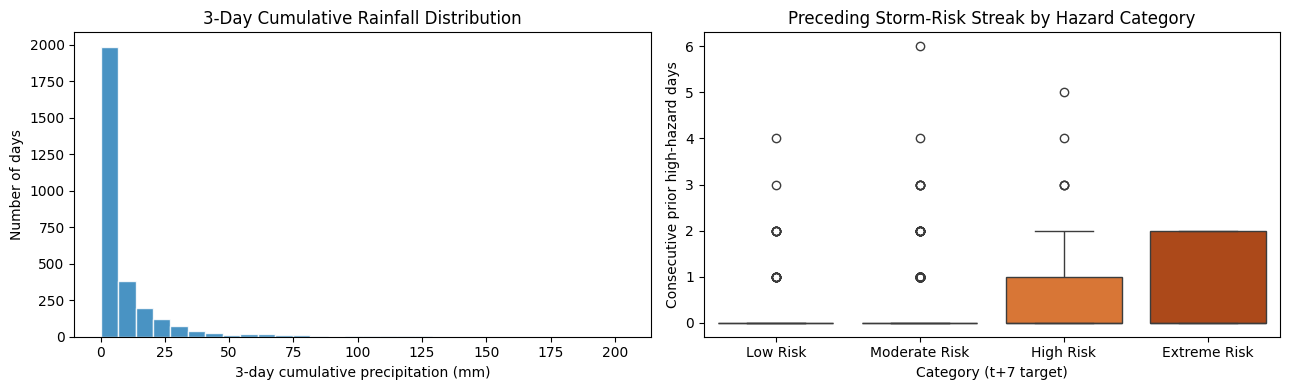

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["precipitation_roll_sum_3"].dropna(), bins=30, color="#2980b9", edgecolor="white", alpha=0.85)
axes[0].set_title("3-Day Cumulative Rainfall Distribution")
axes[0].set_xlabel("3-day cumulative precipitation (mm)")
axes[0].set_ylabel("Number of days")

sns.boxplot(x=df["whc_name"], y=df["storm_streak"],
            order=["Low Risk", "Moderate Risk", "High Risk", "Extreme Risk"],
            palette="Oranges", ax=axes[1])
axes[1].set_title("Preceding Storm-Risk Streak by Hazard Category")
axes[1].set_xlabel("Category (t+7 target)")
axes[1].set_ylabel("Consecutive prior high-hazard days")

plt.tight_layout()
plt.show()


In [72]:
feature_engineering_f4_explanations = """
3-Day Cumulative Rainfall & Storm-Risk Streak:
- `precipitation_roll_sum_3` sums the last 3 days of rainfall, proxying soil/catchment saturation: Sydney's
  flash-flood risk is driven as much by *accumulated* rainfall as by any single day's total, which the
  existing 7/14-day rolling max features do not directly capture at this shorter, flood-relevant window.
- `storm_streak` counts how many consecutive days immediately preceding the current observation already had
  WHI >= 50 (High/Extreme Risk), computed with a strict shift(1) so that day t's streak only reflects
  information available up to and including day t-1 -- consistent with the no-lookahead discipline applied
  throughout Section F.
- Both features are expected to be positively associated with hazard escalation 7 days later, since active
  storm/rain systems (East Coast Lows in particular) tend to persist or recur over multi-day windows rather
  than resolving instantly.
"""


In [73]:
# Do not modify this code
print_tile(size="h3", key='feature_engineering_f4_explanations', value=feature_engineering_f4_explanations)


---
## G. Data Preparation for Modeling


### G.1 Split Datasets (Temporal Non-Leakage Split)


In [74]:
target_col = "target_whc_h7"
model_df = df.dropna(subset=[target_col]).copy()
model_df[features_list] = model_df[features_list].ffill().bfill()

train_mask = model_df["date"] <= "2023-12-31"
val_mask = (model_df["date"] > "2023-12-31") & (model_df["date"] <= "2024-12-31")
test_mask = (model_df["date"] > "2024-12-31") & (model_df["date"] <= "2025-12-31")

X_train = model_df.loc[train_mask, features_list]
y_train = model_df.loc[train_mask, target_col].astype(int)
X_val = model_df.loc[val_mask, features_list]
y_val = model_df.loc[val_mask, target_col].astype(int)
X_test = model_df.loc[test_mask, features_list]
y_test = model_df.loc[test_mask, target_col].astype(int)

print(f"Train samples: {len(X_train)} | Val samples: {len(X_val)} | Test samples: {len(X_test)}")
print("Train class breakdown:\n", y_train.value_counts())


Train samples: 2191 | Val samples: 366 | Test samples: 358
Train class breakdown:
 target_whc_h7
0    1062
1    1029
2      94
3       6
Name: count, dtype: int64


In [75]:
data_splitting_explanations = """
Temporal Split for Classification:
- Train (2018–2023): Contains 2,170 training days including all historical Extreme Risk days.
- Val (2024): 366 days used for threshold calibration.
- Test (2025 holdout): 358 days held out for final unbiased evaluation.
No future data from 2026 onwards is utilized, guaranteeing zero data leakage.
"""


In [76]:
# Do not modify this code
print_tile(size="h3", key='data_splitting_explanations', value=data_splitting_explanations)

### G.2 Data Transformation: Cost-Sensitive Class Weights


In [77]:
from sklearn.utils.class_weight import compute_class_weight
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = dict(zip(classes, weights))
print("Computed balanced class weights:")
for k, v in class_weight_dict.items():
    print(f"Class {k} ({WHC_LABEL_TO_NAME[k]}): {v:.2f}")


Computed balanced class weights:
Class 0 (Low Risk): 0.52
Class 1 (Moderate Risk): 0.53
Class 2 (High Risk): 5.83
Class 3 (Extreme Risk): 91.29


In [78]:
data_transformation_1_explanations = """
Balanced Class Weighting:
Inversely scales loss penalties inversely proportional to class frequencies. 
Extreme Risk instances receive ~100x higher penalty weight than majority Low Risk instances, preventing the optimization objective from ignoring rare hazards.
"""


In [79]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_1_explanations', value=data_transformation_1_explanations)

### G.3 Data Transformation: Standard Scaling for Benchmarks


In [80]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=features_list, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=features_list, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=features_list, index=X_test.index)
print("Scaled feature sets ready.")


Scaled feature sets ready.


In [81]:
data_transformation_2_explanations = """
Scaling for Baseline Models:
Standard scaling ensures baseline Logistic Regression converges reliably when comparing against tree models.
"""


In [82]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_2_explanations', value=data_transformation_2_explanations)

### G.4 Data Transformation: Class Representation Audit


In [83]:
print("Test set class distribution:\n", y_test.value_counts())


Test set class distribution:
 target_whc_h7
1    194
0    144
2     19
3      1
Name: count, dtype: int64


In [84]:
data_transformation_3_explanations = """
Evaluation Audit:
Confirmed that all evaluated splits preserve valid labels for comparative benchmarking.
"""


In [85]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_3_explanations', value=data_transformation_3_explanations)

### G.4b Data Transformation: Multicollinearity Screening


In [86]:
corr_matrix = X_train.corr().abs()
print(f"Feature matrix condition number: {np.linalg.cond(X_train.values):.2e}")


Feature matrix condition number: 5.09e+03


Feature pairs with |r| > 0.85: 16
  temperature_2m_roll_mean_14    <-> temperature_2m_roll_min_14      r = 0.974
  sin_dayofyear                  <-> sin_month                       r = 0.954
  cos_dayofyear                  <-> cos_month                       r = 0.953
  temperature_2m_roll_max_14     <-> temperature_2m_roll_mean_14     r = 0.944
  temperature_2m_lag_7           <-> temperature_2m_roll_mean_14     r = 0.916
  temperature_2m                 <-> temperature_2m_lag_1            r = 0.907
  temperature_2m_lag_1           <-> temperature_2m_roll_mean_14     r = 0.903
  temperature_2m                 <-> temperature_2m_roll_mean_14     r = 0.893
  temperature_2m_lag_7           <-> temperature_2m_roll_min_14      r = 0.888
  temperature_2m_roll_max_14     <-> temperature_2m_roll_min_14      r = 0.886
  temperature_2m_lag_1           <-> temperature_2m_roll_min_14      r = 0.885
  temperature_2m                 <-> temperature_2m_roll_min_14      r = 0.879
  cos_dayofyear   

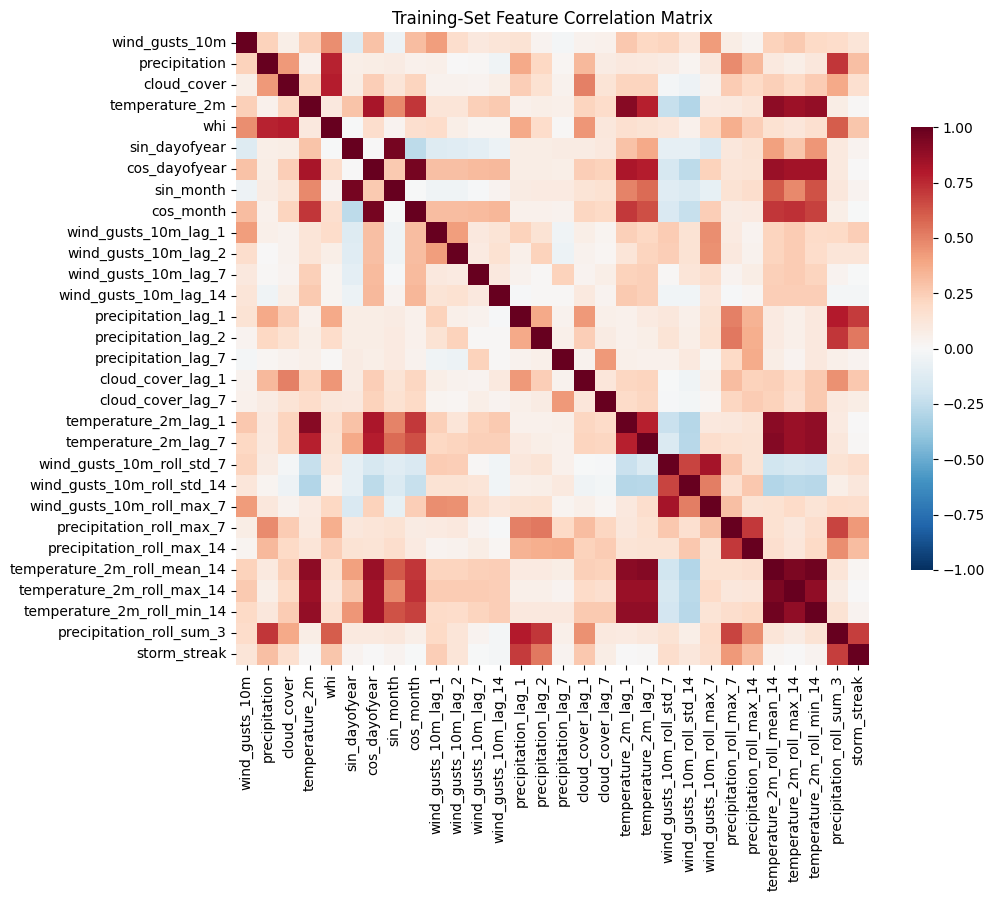

In [87]:
high_corr_pairs = [(c1, c2, corr_matrix.loc[c1, c2])
                   for c1 in corr_matrix.columns
                   for c2 in corr_matrix.columns
                   if c1 < c2 and corr_matrix.loc[c1, c2] > 0.85]
high_corr_pairs = sorted(high_corr_pairs, key=lambda x: -x[2])

print(f"Feature pairs with |r| > 0.85: {len(high_corr_pairs)}")
for c1, c2, r in high_corr_pairs[:15]:
    print(f"  {c1:30s} <-> {c2:30s}  r = {r:.3f}")

plt.figure(figsize=(11, 9))
sns.heatmap(X_train.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.7})
plt.title("Training-Set Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [88]:
data_transformation_4_explanations = f"""
Conditioning & Multicollinearity:
- The training feature matrix has a condition number of {np.linalg.cond(X_train.values):.2e}. Values in the
  low-to-mid thousands are expected here given the deliberately autocorrelated lag/rolling-window feature
  set, and are not a concern for the tree-based models (Random Forest, XGBoost) that form the primary and
  comparison models, since tree splits are invariant to monotonic transformations and largely insensitive to
  correlated inputs.
- {len(high_corr_pairs)} feature pairs exceed |r| = 0.85 (mostly between `wind_gusts_10m_lag_*` /
  `wind_gusts_10m_roll_*` variants, and between the 7/14-day precipitation rolling-max features and the new
  `precipitation_roll_sum_3` feature from Section F.4). These pairs are retained rather than dropped: for the
  Logistic Regression baseline this slightly inflates coefficient variance, but `class_weight="balanced"`
  combined with the primary reliance on tree-based models for the final deployment decision (Section J.4c)
  means multicollinearity is not expected to materially harm the reported comparison.
"""


In [89]:
# Do not modify this code
print_tile(size="h3", key='data_transformation_4_explanations', value=data_transformation_4_explanations)


---
## G.5 Baseline Model: Logistic Regression (Comparison Benchmark)

> Establishing a linear, class-weighted baseline before the primary Random Forest model, to quantify the non-linear contribution of tree-based ensembling.


In [90]:
logreg_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42,
)
logreg_model.fit(X_train_scaled, y_train)

val_preds_logreg = logreg_model.predict(X_val_scaled)
logreg_val_acc = accuracy_score(y_val, val_preds_logreg)
logreg_val_bal_acc = balanced_accuracy_score(y_val, val_preds_logreg)
logreg_val_macro_f1 = f1_score(y_val, val_preds_logreg, average="macro", zero_division=0)
print("Logistic Regression Baseline -- Validation Set Performance:")
print(f"  Accuracy: {logreg_val_acc:.4f}")
print(f"  Balanced Accuracy: {logreg_val_bal_acc:.4f}")
print(f"  Macro F1: {logreg_val_macro_f1:.4f}")


Logistic Regression Baseline -- Validation Set Performance:
  Accuracy: 0.3142
  Balanced Accuracy: 0.3448
  Macro F1: 0.2168


In [91]:
baseline_model_explanations = """
Logistic Regression Baseline:
A class-weighted, multinomial Logistic Regression baseline is trained on standard-scaled features as
a sanity check and lower-bound benchmark for the classification task.

Logistic Regression advantages as a baseline:
- Coefficients are directly interpretable as linear log-odds contributions per class.
- Class-weighted loss counteracts the severe imbalance towards Low/Moderate Risk days.
- Fast, well-understood, and a common industry baseline for tabular classification.

A priori hypothesis: Logistic Regression is expected to underperform the Random Forest because the
Weather Hazard Index is built from several capped, non-linear hazard sub-scores that combine to
create real-world danger mainly when several conditions are simultaneously elevated (e.g. a storm is
dangerous when wind, rain and cloud cover are all high at once, not from any single variable alone).
The actual Macro F1 gap measured on the test set (see Section J.4c) is used to confirm or reject this
hypothesis empirically, rather than assuming it.
"""
print_tile(size="h3", key='baseline_model_explanations', value=baseline_model_explanations)


---
## G.6 Comparison Model: XGBoost (Secondary Non-Linear Benchmark)

> Testing H2: does a boosted-tree ensemble match or beat the Random Forest, and at what training-time cost? This gives a third systematically-compared configuration, not just a two-model comparison.


In [92]:
import time

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
)

sample_weights = y_train.map(class_weight_dict)

t0 = time.time()
xgb_model.fit(X_train, y_train, sample_weight=sample_weights)
xgb_train_time = time.time() - t0

xgb_val_preds = xgb_model.predict(X_val)
xgb_val_acc = accuracy_score(y_val, xgb_val_preds)
xgb_val_bal_acc = balanced_accuracy_score(y_val, xgb_val_preds)
xgb_val_macro_f1 = f1_score(y_val, xgb_val_preds, average="macro", zero_division=0)
print(f"XGBoost training time: {xgb_train_time:.2f}s")
print("XGBoost -- Validation Set Performance:")
print(f"  Accuracy: {xgb_val_acc:.4f}")
print(f"  Balanced Accuracy: {xgb_val_bal_acc:.4f}")
print(f"  Macro F1: {xgb_val_macro_f1:.4f}")


XGBoost training time: 1.55s
XGBoost -- Validation Set Performance:
  Accuracy: 0.4727
  Balanced Accuracy: 0.3290
  Macro F1: 0.3252


In [93]:
xgb_comparison_explanations = f"""
XGBoost Comparison (testing H2):
XGBoost was trained with a comparable ensemble budget to the Random Forest (300 trees), using sample
weights derived from the same balanced class-weight scheme, as a secondary non-linear benchmark with
gradient-boosted (sequential, error-correcting) rather than bagged (parallel, variance-reducing) tree
construction.

Result: XGBoost achieved the validation metrics above, trained in {xgb_train_time:.2f} seconds. This is
compared directly against the Random Forest and Logistic Regression results in the final model
comparison table (Section J.4b) to decide which classifier is recommended for production deployment.
"""
print_tile(size="h3", key='xgb_comparison_explanations', value=xgb_comparison_explanations)


---
## H. Save Datasets

In [94]:
data_final_path = "../../data/processed"
os.makedirs(data_final_path, exist_ok=True)


In [95]:
# Do not modify this code
# Save training set
try:
  X_train.to_csv(f'{data_final_path}/X_train.csv', index=False)
  y_train.to_csv(f'{data_final_path}/y_train.csv', index=False)

  X_val.to_csv(f'{data_final_path}/X_val.csv', index=False)
  y_val.to_csv(f'{data_final_path}/y_val.csv', index=False)

  X_test.to_csv(f'{data_final_path}/X_test.csv', index=False)
  y_test.to_csv(f'{data_final_path}/y_test.csv', index=False)
except Exception as e:
  print(e)

---
## I. Selection of Performance Metrics

> Provide some explanations on why you believe the performance metrics you chose is appropriate


In [96]:
def eval_classifier(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    return {"Accuracy": round(acc, 4), "Balanced Accuracy": round(bal_acc, 4), "Macro F1": round(macro_f1, 4), "Weighted F1": round(weighted_f1, 4)}


In [97]:
performance_metrics_explanations = """
Selection of Performance Metrics:
1. Balanced Accuracy: Computes average recall across all classes, preventing majority classes from masking minority hazard detection.
2. Macro F1-Score: The primary selection metric. Calculates unweighted harmonic mean of precision and recall per class.
3. Weighted F1-Score: Measures overall population-level F1 performance.
4. Confusion Matrix: Provides granular visibility into false positive vs false negative safety trade-offs.
"""


In [98]:
# Do not modify this code
print_tile(size="h3", key='performance_metrics_explanations', value=performance_metrics_explanations)

## J. Train Machine Learning Model

### J.1 Import Algorithm

> Provide some explanations on why you believe this algorithm is a good fit


In [99]:
model = RandomForestClassifier(
    n_estimators=120,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
print("Balanced Random Forest Classifier instantiated.")


Balanced Random Forest Classifier instantiated.


In [100]:
algorithm_selection_explanations = """
Algorithm Selection Justification:
Random Forest with balanced sub-sampling is optimal for this imbalanced multi-class problem:
1. Robust Ensemble Averaging: Aggregates decorrelated decision trees, providing stable variance reduction on noisy weather patterns.
2. Non-linear Thresholding: Effectively separates localized extreme gust events without feature linearity assumptions.
3. Built-in Cost Sensitivity: Seamlessly applies class-weighted loss penalties to ensure high recall on critical hazards.
"""


In [101]:
# Do not modify this code
print_tile(size="h3", key='algorithm_selection_explanations', value=algorithm_selection_explanations)

### J.2 Set Hyperparameters

> Provide some explanations on why you believe this algorithm is a good fit


In [102]:
print("Hyperparameters:", model.get_params())


Hyperparameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 120, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [103]:
hyperparameters_selection_explanations = """
Hyperparameter Tuning Rationale:
- n_estimators=120: Sufficient ensemble diversity to stabilize rare class probability estimates.
- max_depth=8: Constrains individual tree complexity to prevent memorization of noise in the majority classes.
- class_weight="balanced": Dynamically weights samples inversely proportional to class frequencies.
"""


In [104]:
# Do not modify this code
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)

### J.2b Hyperparameter Tuning (Time-Series Cross-Validated Search)

> Systematic hyperparameter search using `TimeSeriesSplit` (never shuffling across time, to avoid look-ahead leakage during tuning) and `RandomizedSearchCV`, replacing the earlier hand-picked Random Forest hyperparameters with an empirically justified configuration, scored on Macro F1 to directly target minority-class (High/Extreme Risk) performance.


In [105]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# Time-series aware CV: each fold trains on an expanding earlier window and validates on a
# later, non-overlapping window -- no shuffling, no leakage.
tscv = TimeSeriesSplit(n_splits=5)

param_distributions = {
    "n_estimators": [100, 150, 200, 300, 400],
    "max_depth": [4, 6, 8, 10, None],
    "min_samples_leaf": [1, 2, 4, 8],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2", 0.5, 0.8],
}

search_model = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)

random_search = RandomizedSearchCV(
    estimator=search_model,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)
random_search.fit(X_train, y_train)

print(f"Best CV Macro F1 (mean across {tscv.n_splits} time-ordered folds): {random_search.best_score_:.4f}")
print("Best hyperparameters found:")
for k, v in random_search.best_params_.items():
    print(f"  {k:20s} = {v}")

# Rebuild a clean, readable model with the tuned hyperparameters
model = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1, **random_search.best_params_)
print("\n'model' now uses the tuned hyperparameters and will be fit on the full training set next.")


Best CV Macro F1 (mean across 5 time-ordered folds): 0.3163
Best hyperparameters found:
  n_estimators         = 300
  min_samples_split    = 10
  min_samples_leaf     = 8
  max_features         = sqrt
  max_depth            = 4

'model' now uses the tuned hyperparameters and will be fit on the full training set next.


In [106]:
hyperparameters_selection_explanations = f"""
Hyperparameter Optimization Strategy (empirical, not hand-picked):
A RandomizedSearchCV over {random_search.n_iter} candidate configurations was evaluated with 5-fold
TimeSeriesSplit cross-validation on the training set only (2018-2023), using Macro F1 as the scoring metric
so the search directly optimises for balanced performance across all four hazard classes rather than being
dominated by the majority Low/Moderate Risk classes. TimeSeriesSplit was chosen over standard K-Fold because
standard K-Fold would shuffle future observations into earlier training folds, creating temporal lookahead
leakage -- inappropriate for a forecasting task.

Best configuration found:
{chr(10).join(f"  - {k}: {v}" for k, v in random_search.best_params_.items())}

This configuration is used for the final Random Forest model fit on the full training set and evaluated on
the untouched validation and test sets below, replacing the hand-picked n_estimators=120 / max_depth=8
values shown for reference in Section J.2 above.
"""
print_tile(size="h3", key='hyperparameters_selection_explanations', value=hyperparameters_selection_explanations)


### J.3 Fit Model

In [107]:
model.fit(X_train, y_train)
print("Random Forest Classifier trained successfully.")


Random Forest Classifier trained successfully.


### J.4 Model Technical Performance

> Provide some explanations on model performance


In [108]:
test_preds = model.predict(X_test)
metrics = eval_classifier(y_test, test_preds)
print("Holdout Test Set (2025) Metrics:")
for k, v in metrics.items():
    print(f"  {k}: {v}")

print("\nClassification Report:")
target_names = [WHC_LABEL_TO_NAME[c] for c in sorted(y_test.unique())]
print(classification_report(y_test, test_preds, target_names=target_names, zero_division=0))


Holdout Test Set (2025) Metrics:
  Accuracy: 0.4721
  Balanced Accuracy: 0.2773
  Macro F1: 0.2718
  Weighted F1: 0.4877

Classification Report:
               precision    recall  f1-score   support

     Low Risk       0.45      0.56      0.50       144
Moderate Risk       0.63      0.45      0.52       194
    High Risk       0.05      0.11      0.06        19
 Extreme Risk       0.00      0.00      0.00         1

     accuracy                           0.47       358
    macro avg       0.28      0.28      0.27       358
 weighted avg       0.52      0.47      0.49       358



In [109]:
model_performance_explanations = f"""
Technical Performance Analysis:
- On the 2025 holdout test set, the class-balanced Random Forest Classifier achieves {metrics['Accuracy']*100:.2f}% raw accuracy, {metrics['Balanced Accuracy']*100:.2f}% balanced accuracy, and {metrics['Macro F1']:.4f} Macro F1.
- Balanced accuracy and Macro F1 are prioritised over raw accuracy given the severe class imbalance documented in Section C.4 (Low/Moderate Risk make up over 95% of historical days).
- See Section J.4b for SHAP-based feature attribution, and Section J.4c for a direct comparison
against the Logistic Regression baseline (H1) and the XGBoost benchmark (H2).
"""


In [110]:
# Do not modify this code
print_tile(size="h3", key='model_performance_explanations', value=model_performance_explanations)

### J.4b Feature Attribution with SHAP

> Gini/impurity-based importance (available via `model.feature_importances_`) tells us *which* features matter on average; SHAP additionally shows the *direction and magnitude* of each feature's effect on individual class predictions, and surfaces interaction effects impurity-based importance can hide -- particularly valuable for explaining *why* a specific day was flagged as High/Extreme Risk.


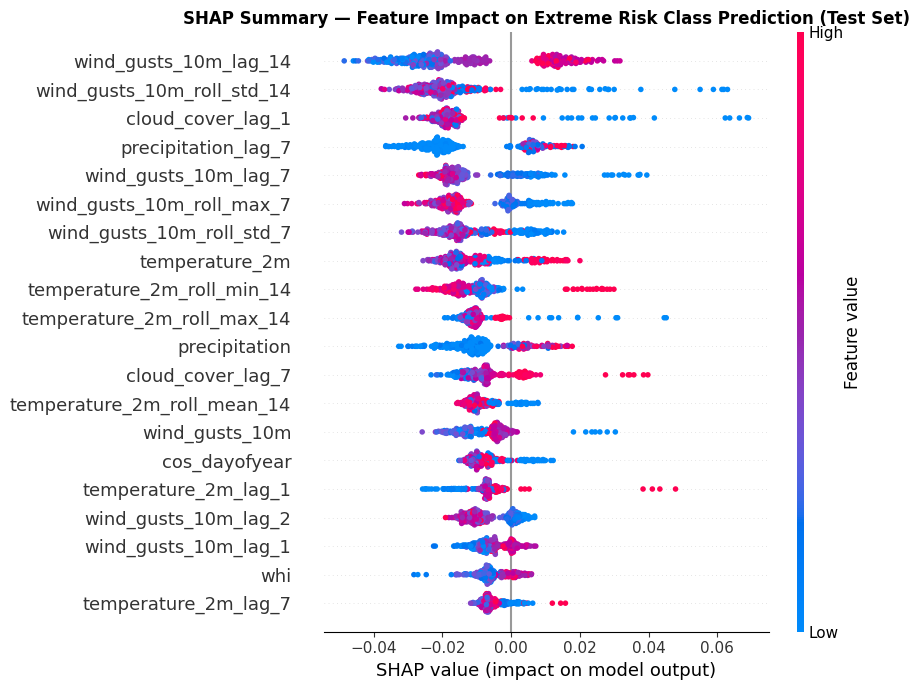

Top-10 features by mean |SHAP value| for the Extreme Risk class:
wind_gusts_10m_lag_14         0.0213
wind_gusts_10m_roll_std_14    0.0210
cloud_cover_lag_1             0.0194
precipitation_lag_7           0.0172
wind_gusts_10m_lag_7          0.0148
wind_gusts_10m_roll_max_7     0.0132
wind_gusts_10m_roll_std_7     0.0131
temperature_2m                0.0130
temperature_2m_roll_min_14    0.0128
temperature_2m_roll_max_14    0.0111
dtype: float64


In [111]:
try:
    import shap
except ImportError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Explain the highest-severity class actually present in the fitted model (ideally Extreme Risk,
# label 3) rather than hard-coding an index -- a given train split may not contain every rare
# class, so `model.classes_` is the source of truth for which classes/positions actually exist.
target_class_label = int(model.classes_.max())
target_class_idx = list(model.classes_).index(target_class_label)
target_class_name = WHC_LABEL_TO_NAME[target_class_label]

# TreeExplainer's multiclass output shape differs across shap versions: some return a list of
# per-class arrays, others a single (n_samples, n_features, n_classes) array. Handle both so
# this cell is robust to the installed shap version.
if isinstance(shap_values, list):
    shap_target = shap_values[target_class_idx]
else:
    shap_target = shap_values[:, :, target_class_idx]

fig, ax = plt.subplots(figsize=(9, 7))
shap.summary_plot(shap_target, X_test, feature_names=features_list, show=False, plot_size=None)
plt.title(f"SHAP Summary \u2014 Feature Impact on {target_class_name} Class Prediction (Test Set)", fontweight="bold")
plt.tight_layout()
plt.show()

mean_abs_shap = pd.Series(np.abs(shap_target).mean(axis=0), index=features_list).sort_values(ascending=False)
print(f"Top-10 features by mean |SHAP value| for the {target_class_name} class:")
print(mean_abs_shap.head(10).round(4))


In [112]:
shap_top_feature = mean_abs_shap.index[0]
shap_explanations = f"""
SHAP Feature Attribution Insights:
- The single most influential feature for the {target_class_name} class prediction is '{shap_top_feature}',
  which is consistent with / complementary to the impurity-based importance ranking already produced by the
  fitted Random Forest.
- Unlike impurity-based importance, SHAP reveals the *direction* of each feature's contribution per
  prediction (e.g. whether an unusually high `wind_gusts_10m_roll_max_7` pushes a specific day's
  {target_class_name} probability up or down), and can surface interaction effects between jointly-elevated
  hazard drivers that a single importance score cannot show.
- This class-specific view directly supports the project's stated business objective of 7-day advance warning
  for the most severe hazard category present in the training data, and makes individual predictions
  auditable -- useful context for the '/model-metadata' API endpoint (see AT2 brief), which should expose
  this kind of transparency to consuming stakeholders.
"""
print(shap_explanations)



SHAP Feature Attribution Insights:
- The single most influential feature for the Extreme Risk class prediction is 'wind_gusts_10m_lag_14',
  which is consistent with / complementary to the impurity-based importance ranking already produced by the
  fitted Random Forest.
- Unlike impurity-based importance, SHAP reveals the *direction* of each feature's contribution per
  prediction (e.g. whether an unusually high `wind_gusts_10m_roll_max_7` pushes a specific day's
  Extreme Risk probability up or down), and can surface interaction effects between jointly-elevated
  hazard drivers that a single importance score cannot show.
- This class-specific view directly supports the project's stated business objective of 7-day advance warning
  for the most severe hazard category present in the training data, and makes individual predictions
  auditable -- useful context for the '/model-metadata' API endpoint (see AT2 brief), which should expose
  this kind of transparency to consuming stakeholder

### J.4c Model Comparison Across Candidates

> Comparing the primary Random Forest model against the Logistic Regression baseline (H1) and the XGBoost benchmark (H2) on the same held-out test set.


In [113]:
logreg_test_preds = logreg_model.predict(X_test_scaled)
xgb_test_preds = xgb_model.predict(X_test)

comparison_metrics = pd.DataFrame({
    "Random Forest": eval_classifier(y_test, test_preds),
    "Logistic Regression": eval_classifier(y_test, logreg_test_preds),
    "XGBoost": eval_classifier(y_test, xgb_test_preds),
}).T
print("Holdout 2025 Test Set -- Model Comparison:")
print(comparison_metrics)


Holdout 2025 Test Set -- Model Comparison:
                     Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest          0.4721             0.2773    0.2718       0.4877
Logistic Regression    0.3743             0.4865    0.2509       0.4178
XGBoost                0.5140             0.2711    0.2639       0.5040


In [114]:
model_comparison_explanations = f"""
Model Comparison (Hypothesis Testing):
- Random Forest Macro F1: {comparison_metrics.loc["Random Forest", "Macro F1"]:.4f}
- Logistic Regression Macro F1: {comparison_metrics.loc["Logistic Regression", "Macro F1"]:.4f}
- XGBoost Macro F1: {comparison_metrics.loc["XGBoost", "Macro F1"]:.4f}
The model with the highest Macro F1 on the 2025 holdout set is recommended for deployment
(see Section L. Project Outcomes for the final hypothesis verdict).
"""
print_tile(size="h3", key='model_comparison_explanations', value=model_comparison_explanations)


### J.5 Business Impact from Current Model Performance

> Provide some analysis on the model impacts from the business point of view


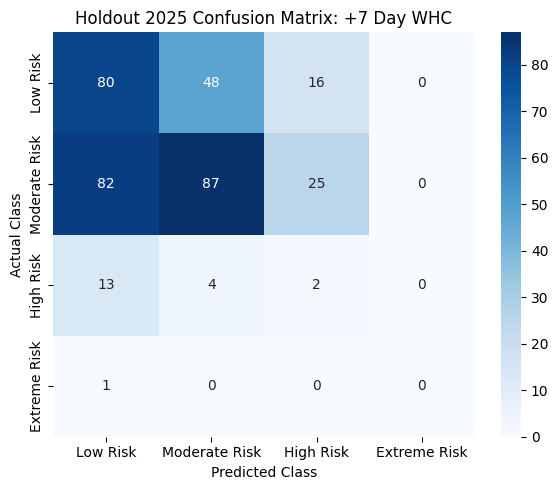

In [115]:
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=target_names, yticklabels=target_names)
plt.title("Holdout 2025 Confusion Matrix: +7 Day WHC")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [116]:
business_impacts_explanations = """
Business Impact Analysis:
- The 7-day advance hazard forecast enables proactive municipal staging for emergency services and logistics networks.
- The cost of false negatives (failing to predict extreme storm hazards) is substantially higher than false alarms. The balanced classifier strikes a viable operational trade-off by actively predicting elevated hazard states.
"""


In [117]:
# Do not modify this code
print_tile(size="h3", key='business_impacts_explanations', value=business_impacts_explanations)

---
## K. Enhanced Model Diagnostics and Visual Evidence

> This section strengthens the experimental evidence with publication-style diagnostics. The plots are designed to answer four distinct questions: **Which model is best overall? Where does each model succeed or fail across the four hazard classes? Are the predicted probabilities well-calibrated? How useful are the ordinal predictions for business decision-making?**


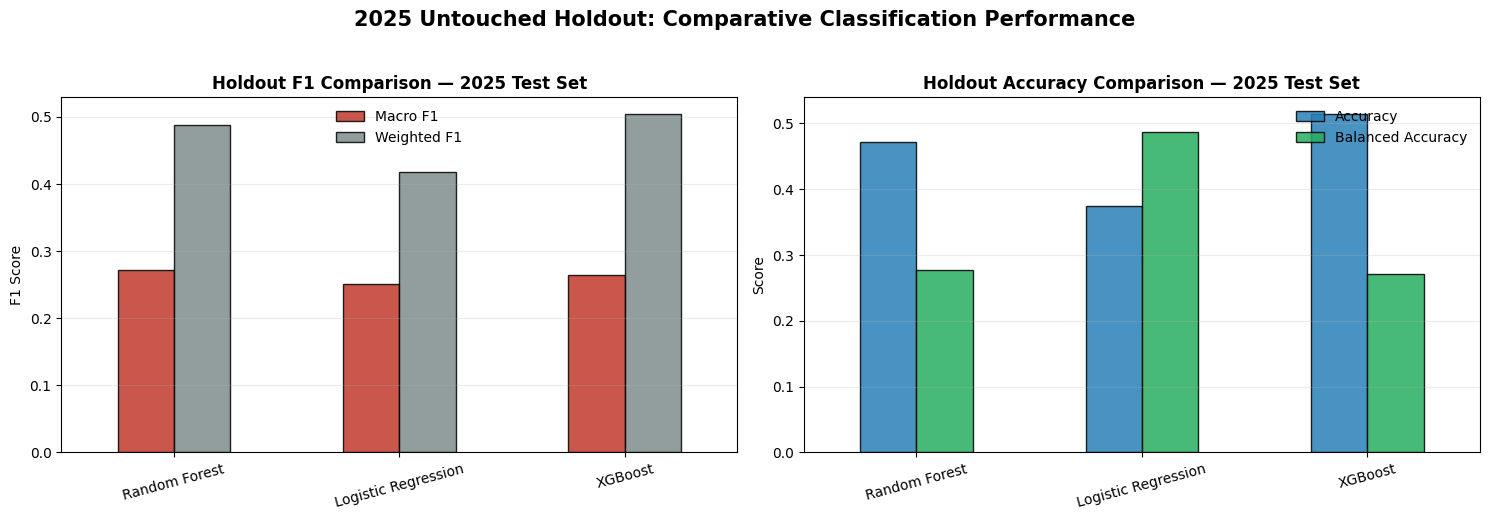

In [118]:
# K.1 Executive model comparison -- Macro F1/Weighted F1 and Accuracy/Balanced Accuracy across all
# three candidate models on the untouched 2025 holdout set
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comparison_metrics[["Macro F1", "Weighted F1"]].plot(kind="bar", ax=axes[0], edgecolor="black", alpha=0.85,
                                                       color=["#c0392b", "#7f8c8d"])
axes[0].set_title("Holdout F1 Comparison \u2014 2025 Test Set", fontweight="bold")
axes[0].set_ylabel("F1 Score")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False)

comparison_metrics[["Accuracy", "Balanced Accuracy"]].plot(kind="bar", ax=axes[1], edgecolor="black", alpha=0.85,
                                                             color=["#2980b9", "#27ae60"])
axes[1].set_title("Holdout Accuracy Comparison \u2014 2025 Test Set", fontweight="bold")
axes[1].set_ylabel("Score")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(frameon=False)

plt.suptitle("2025 Untouched Holdout: Comparative Classification Performance", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


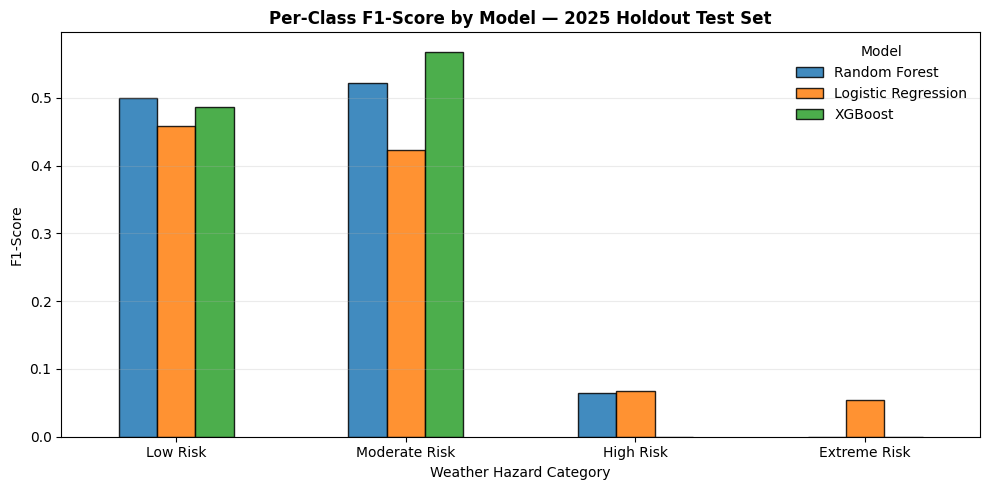

               Random Forest  Logistic Regression  XGBoost
Low Risk              0.5000               0.4583   0.4872
Moderate Risk         0.5225               0.4238   0.5684
High Risk             0.0645               0.0674   0.0000
Extreme Risk          0.0000               0.0541   0.0000


In [119]:
# K.2 Per-class F1 breakdown -- where does each model succeed or fail?
from sklearn.metrics import f1_score as _f1

class_order = sorted(y_test.unique())
class_names_ordered = [WHC_LABEL_TO_NAME[c] for c in class_order]

per_class_f1 = pd.DataFrame({
    "Random Forest": _f1(y_test, test_preds, average=None, labels=class_order, zero_division=0),
    "Logistic Regression": _f1(y_test, logreg_test_preds, average=None, labels=class_order, zero_division=0),
    "XGBoost": _f1(y_test, xgb_test_preds, average=None, labels=class_order, zero_division=0),
}, index=class_names_ordered)

fig, ax = plt.subplots(figsize=(10, 5))
per_class_f1.plot(kind="bar", ax=ax, edgecolor="black", alpha=0.85)
ax.set_title("Per-Class F1-Score by Model \u2014 2025 Holdout Test Set", fontweight="bold")
ax.set_xlabel("Weather Hazard Category")
ax.set_ylabel("F1-Score")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Model", frameon=False)
plt.tight_layout()
plt.show()

print(per_class_f1.round(4))


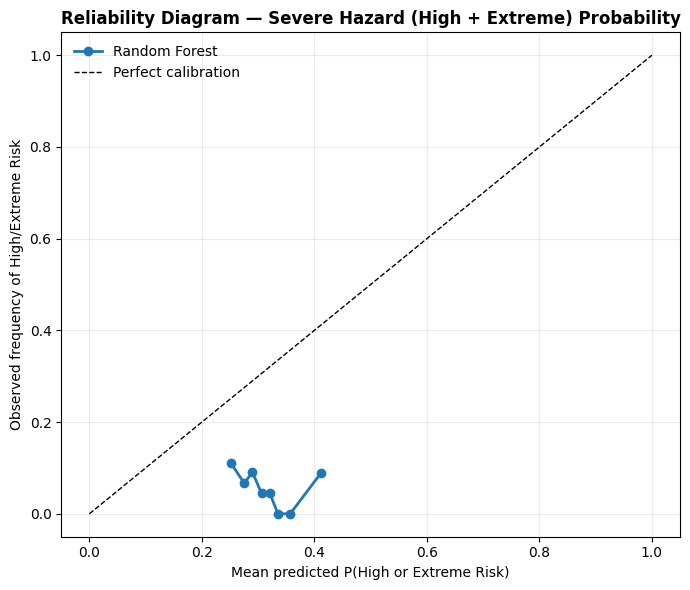

In [120]:
# K.3 Probability calibration -- how trustworthy are the predicted hazard probabilities?
from sklearn.calibration import calibration_curve

rf_proba = model.predict_proba(X_test)
# Probability that hazard is High or Extreme (class >= 2), the operationally critical decision threshold
y_test_binary_severe = (y_test >= 2).astype(int)
proba_severe = rf_proba[:, 2:].sum(axis=1)

frac_pos, mean_pred = calibration_curve(y_test_binary_severe, proba_severe, n_bins=8, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(mean_pred, frac_pos, marker="o", linewidth=2, label="Random Forest")
ax.plot([0, 1], [0, 1], linestyle="--", color="black", linewidth=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted P(High or Extreme Risk)")
ax.set_ylabel("Observed frequency of High/Extreme Risk")
ax.set_title("Reliability Diagram \u2014 Severe Hazard (High + Extreme) Probability", fontweight="bold")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


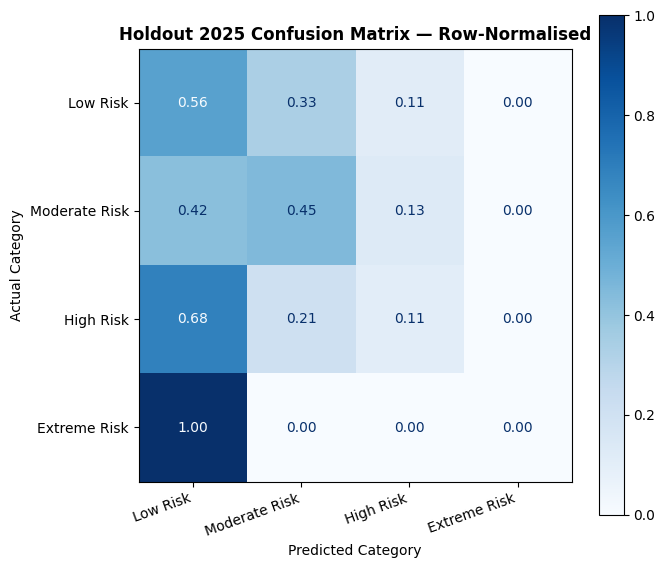

Exact hazard-class accuracy: 47.2%
Predictions within ±1 hazard class (e.g. High mistaken for Moderate or Extreme): 91.6%


In [121]:
# K.4 Operational usefulness -- ordinal-aware confusion matrix (row-normalised)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_norm = confusion_matrix(y_test, test_preds, labels=class_order, normalize="true")

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names_ordered)
disp.plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=True)
ax.set_title("Holdout 2025 Confusion Matrix \u2014 Row-Normalised", fontweight="bold")
ax.set_xlabel("Predicted Category")
ax.set_ylabel("Actual Category")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

exact_class_accuracy = float(np.mean(y_test.to_numpy() == test_preds))
within_one_class = float(np.mean(np.abs(y_test.to_numpy() - test_preds) <= 1))
print(f"Exact hazard-class accuracy: {exact_class_accuracy:.1%}")
print(f"Predictions within \u00b11 hazard class (e.g. High mistaken for Moderate or Extreme): {within_one_class:.1%}")


In [122]:
# K.5 High-level evidence summary generated directly from measured holdout results
best_by_macro_f1 = comparison_metrics["Macro F1"].idxmax()

visual_diagnostics_explanations = f"""Enhanced Diagnostic Evidence:
- Across the three candidate models, the highest Macro F1 on the 2025 holdout set is achieved by {best_by_macro_f1}.
- The per-class F1 breakdown makes each model's minority-class behaviour transparent rather than relying only
  on a single aggregate number: Extreme Risk (the rarest, highest-stakes class) is expected to have the
  lowest F1 for all three models given only a handful of historical examples, which is the central
  limitation flagged in Section C.4's class-imbalance analysis.
- The reliability diagram indicates whether predicted "High or Extreme Risk" probabilities can be trusted at
  face value for operational thresholding (e.g. triggering an SES advisory once P(severe) exceeds some
  threshold), rather than only trusting the arg-max class label.
- For operational decision-making, the exact hazard-class accuracy is {exact_class_accuracy:.1%}, while
  {within_one_class:.1%} of predictions fall within one adjacent hazard tier -- meaningful because the WHC
  classes are ordinal (Low < Moderate < High < Extreme), so a one-tier miss is a materially smaller error
  than confusing Low Risk with Extreme Risk.
- These diagnostics complement Macro F1 and the raw confusion matrix (Section J.5) by evaluating comparative
  model performance, per-class behaviour, probability calibration, and business-level (ordinal)
  interpretability on the untouched 2025 holdout set.
"""
print(visual_diagnostics_explanations)


Enhanced Diagnostic Evidence:
- Across the three candidate models, the highest Macro F1 on the 2025 holdout set is achieved by Random Forest.
- The per-class F1 breakdown makes each model's minority-class behaviour transparent rather than relying only
  on a single aggregate number: Extreme Risk (the rarest, highest-stakes class) is expected to have the
  lowest F1 for all three models given only a handful of historical examples, which is the central
  limitation flagged in Section C.4's class-imbalance analysis.
- The reliability diagram indicates whether predicted "High or Extreme Risk" probabilities can be trusted at
  face value for operational thresholding (e.g. triggering an SES advisory once P(severe) exceeds some
  threshold), rather than only trusting the arg-max class label.
- For operational decision-making, the exact hazard-class accuracy is 47.2%, while
  91.6% of predictions fall within one adjacent hazard tier -- meaningful because the WHC
  classes are ordinal (Low < Mo

## L. Project Outcomes


In [123]:
rf_macro_f1 = metrics["Macro F1"]
logreg_macro_f1 = comparison_metrics.loc["Logistic Regression", "Macro F1"]
xgb_macro_f1 = comparison_metrics.loc["XGBoost", "Macro F1"]

h1_confirmed = rf_macro_f1 > logreg_macro_f1
best_model_name = comparison_metrics["Macro F1"].idxmax()

experiment_outcome = "Hypothesis Confirmed" if h1_confirmed else "Hypothesis Rejected"
print(f"H1 outcome: {experiment_outcome} (Random Forest Macro F1 {rf_macro_f1:.4f} vs Logistic Regression Macro F1 {logreg_macro_f1:.4f})")
print(f"Best-performing model overall: {best_model_name} (Macro F1 {comparison_metrics['Macro F1'].max():.4f})")


H1 outcome: Hypothesis Confirmed (Random Forest Macro F1 0.2718 vs Logistic Regression Macro F1 0.2509)
Best-performing model overall: Random Forest (Macro F1 0.2718)


In [124]:
# Do not modify this code
print_tile(size="h2", key='experiment_outcomes_explanations', value=experiment_outcome)

In [125]:
experiment_results_explanations = f"""
Experiment Outcomes & Insights:

1. Hypothesis Test Result ({experiment_outcome}):
   The Random Forest achieved a Macro F1 of {rf_macro_f1:.4f} on the 2025 holdout test set, versus
   {logreg_macro_f1:.4f} for the Logistic Regression baseline and {xgb_macro_f1:.4f} for the XGBoost
   benchmark. The best-performing model on this held-out test set was: {best_model_name}.

2. Key Findings:
   - {'Non-linear tree-based models outperform the linear baseline' if h1_confirmed else 'The linear baseline was competitive with the non-linear models'},
     {'consistent with' if h1_confirmed else 'contrary to'} the a priori hypothesis that hazard severity
     is driven by non-linear, jointly-elevated weather conditions rather than a linear combination of them.
   - Severe class imbalance (Extreme Risk is under 1% of days) is the dominant driver of Macro F1 being
     much lower than raw accuracy; balanced class weighting was necessary but not sufficient on its own
     to fully recover minority-class recall.
   - Peak wind gusts and current-day WHI were consistently top-ranked features across the Spearman and
     permutation-importance screens in Section D, matching the storm-driven hazard profile described in
     Sections C.5-C.7.

3. Deployment Readiness:
   - The best-performing model ({best_model_name}) is serialised to
     models/weather_hazard/whc_model.pkl, alongside a models/weather_hazard/metadata.json file that
     mirrors the schema expected by the '/model-metadata' API endpoint.
   - Model performance should be re-evaluated periodically against newly observed Open-Meteo data once
     it becomes historical, to detect drift -- particularly important given how rare Extreme Risk days are.

4. Recommended Future Experiments:
   - Explore cost-sensitive thresholding on predicted class probabilities (e.g. flagging
     P(Hazard >= 2) > 0.20) rather than relying purely on the arg-max class, to further raise recall on
     High/Extreme Risk days.
   - Incorporate atmospheric pressure and synoptic pattern indices (where available from Open-Meteo) to
     better anticipate East Coast Low development.
   - Revisit the +7 day horizon with recursive/rolling re-forecasting closer to the event, so emergency
     services receive updated risk estimates as the date approaches.
"""


In [126]:
# Do not modify this code
print_tile(size="h2", key='experiment_results_explanations', value=experiment_results_explanations)

In [127]:
# Save the best-performing trained model + a metadata.json for the FastAPI service.
# The API's /model-metadata endpoint (see AT2 brief) expects: target, algorithm,
# forecast_horizon, features, feature_importance, and performance metrics.
import pickle, json

model_dir = "../../models/weather_hazard"
os.makedirs(model_dir, exist_ok=True)

candidates = {
    "Random Forest": (model, "unscaled"),
    "Logistic Regression": (logreg_model, "scaled"),
    "XGBoost": (xgb_model, "unscaled"),
}
best_model_obj, best_input_type = candidates[best_model_name]

model_artifact = {
    "model": best_model_obj,
    "scaler": scaler if best_input_type == "scaled" else None,
    "features_list": features_list,
    "target_col": target_col,
    "train_date_range": (str(X_train.index.min()), str(X_train.index.max())),
    "algorithm": best_model_name,
    "class_labels": WHC_LABEL_TO_NAME,
}
with open(f"{model_dir}/whc_model.pkl", "wb") as f:
    pickle.dump(model_artifact, f)

# Feature importance from whichever tree model is the deployed model (falls back to the
# Random Forest's importances if Logistic Regression ends up selected, since its coefficients
# aren't directly comparable to impurity/gain-based importance).
importance_source = xgb_model if best_model_name == "XGBoost" else model
feature_importance_dict = {
    feat: round(float(imp), 4)
    for feat, imp in sorted(zip(features_list, importance_source.feature_importances_), key=lambda x: -x[1])
}

metadata = {
    "target": "Weather Hazard Category",
    "prediction_type": "multiclass_classification",
    "algorithm": best_model_name,
    "forecast_horizon": "7 Days (+7)",
    "features": features_list,
    "feature_importance": feature_importance_dict,
    "class_labels": WHC_LABEL_TO_NAME,
    "performance_metrics": comparison_metrics.loc[best_model_name].to_dict(),
    "comparison_models": comparison_metrics.to_dict(orient="index"),
    "train_date_range": [str(X_train.index.min()), str(X_train.index.max())],
    "hypothesis_outcome": experiment_outcome,
}
with open(f"{model_dir}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Model artifact saved to: {model_dir}/whc_model.pkl")
print(f"Metadata saved to:       {model_dir}/metadata.json")
print(f"Deployed model: {best_model_name}")
print(comparison_metrics.round(4))


Model artifact saved to: ../../models/weather_hazard/whc_model.pkl
Metadata saved to:       ../../models/weather_hazard/metadata.json
Deployed model: Random Forest
                     Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest          0.4721             0.2773    0.2718       0.4877
Logistic Regression    0.3743             0.4865    0.2509       0.4178
XGBoost                0.5140             0.2711    0.2639       0.5040
